# DSCI 552 — Homework 6
**Name:** Chengfeng Tang  
**GitHub username:** tcf2021  
**USC ID:** 5488902262

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve
from threadpoolctl import threadpool_limits

ROOT = Path("..") if Path("../data/aps").is_dir() else Path(".")
sys.path.insert(0, str((ROOT / "src").resolve()))
from aps import (SEED, load_csv, medians, filled, transform, prep, LogisticTree,
                 tune, evaluate, SMOTE)
thread_limits = threadpool_limits(limits=4)
DATA, OUT = ROOT / "data/aps", ROOT / "results"
OUT.mkdir(exist_ok=True)
def showfig(file):
    plt.savefig(OUT / (file + ".png"), dpi=135, bbox_inches="tight")
    plt.show()
def answer(s):
    display(Markdown(s))
def table(df, name):
    df.to_csv(OUT / (name + ".csv"), index=False)
    display(df.round(5))

## 1(a). APS Failure at Scania Trucks
A positive observation is an APS component failure. A negative observation is a failure unrelated to the APS. I used the two supplied CSVs and kept the original training/test split.

In [2]:
A, y = load_csv(DATA / "aps_failure_training_set.csv")
B, yt = load_csv(DATA / "aps_failure_test_set.csv")
assert A.columns.equals(B.columns) and A.shape == (60000,170) and B.shape == (16000,170)
print("Training:", A.shape, "  Test:", B.shape)

Training: (60000, 170)   Test: (16000, 170)


## 1(b)(i). Missing values
Mean or median imputation uses one value per feature. K-nearest-neighbor imputation uses similar complete or partially observed cases; iterative imputation estimates each incomplete feature from the others. I used the median because a few large sensor readings can move the mean substantially. I retained zeros as measurements.

For the final test predictions, I followed footnote 1 and computed medians from the **unlabeled test features**. This is a batch prediction setting. During cross-validation, I used only each training fold to learn medians and scaling. A feature with no observed values in the imputation batch would receive zero.

In [3]:
ma, mb = medians(A), medians(B)
X, T = filled(A,ma), filled(B,mb)
print("Missing entries — training:", int(A.isna().sum().sum()), " test:", int(B.isna().sum().sum()))
assert np.isfinite(X).all() and np.isfinite(T).all()
train = pd.DataFrame(X, columns=A.columns, copy=False)

Missing entries — training: 850015  test: 228680


## 1(b)(ii). Coefficients of variation
For each imputed training feature, I calculated the sample standard deviation ($s$, denominator $n-1$) divided by the mean. A zero mean gives an undefined CV; those features are excluded from the ranking.

In [4]:
mean = train.astype("float64").mean()
sd = train.astype("float64").std(ddof=1)
cv = pd.DataFrame({"feature":A.columns, "mean":mean.values, "sample_sd":sd.values,
                   "CV":(sd / mean.replace(0,np.nan)).values}).sort_values("CV",ascending=False)
top = cv.dropna(subset=["CV"]).head(int(np.sqrt(A.shape[1]))).feature.tolist()
with pd.option_context("display.max_rows", 175):
    table(cv.reset_index(drop=True), "feature_cv")
print("Undefined CV:", cv.loc[cv.CV.isna(),"feature"].tolist())

Undefined CV: []


,feature,mean,sample_sd,CV
0,cf_000,1.431075e+05,3.504525e+07,244.88752
1,co_000,1.433300e+05,3.504525e+07,244.50739
2,ad_000,1.434383e+05,3.504525e+07,244.32282
3,cs_009,7.705097e+02,1.833278e+05,237.93055
4,dh_000,4.392641e+03,5.412441e+05,123.21610
5,dj_000,3.727133e+01,4.379166e+03,117.49423
6,ag_000,2.191577e+02,2.036364e+04,92.91776
7,as_000,1.254079e+02,1.095219e+04,87.33250
8,ay_009,1.149620e+03,9.741156e+04,84.73373
9,ak_000,9.076607e+02,7.299859e+04,80.42498


## 1(b)(iii). Feature correlations
I used Pearson correlations on all 170 imputed training features. White cells denote undefined correlations with a constant feature. The numeric matrix retains all feature names.

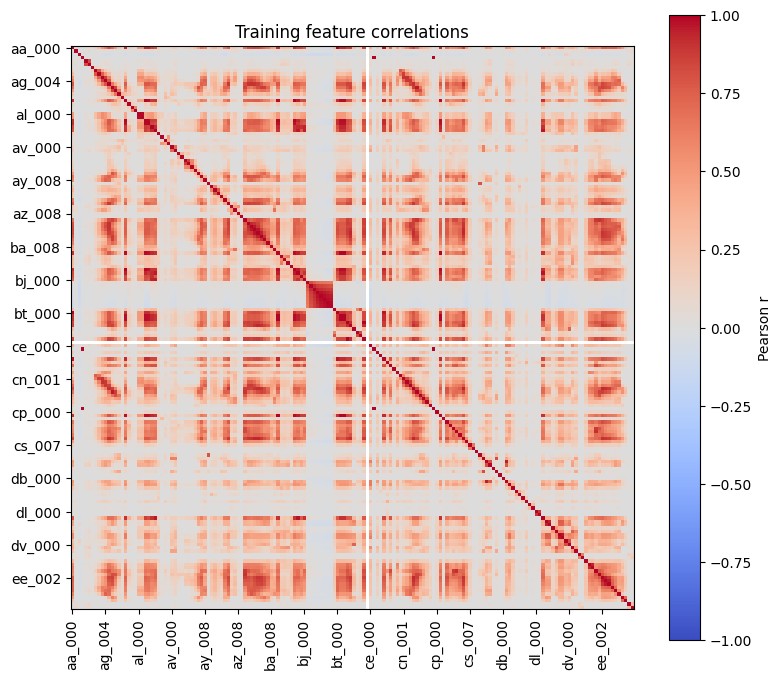

In [5]:
corr = train.corr()
corr.to_csv(OUT / "correlation.csv")
fig,ax=plt.subplots(figsize=(8,7))
im=ax.imshow(corr, vmin=-1,vmax=1,cmap="coolwarm",interpolation="nearest")
ix=np.arange(0,len(corr),10)
ax.set(xticks=ix,xticklabels=corr.columns[ix],yticks=ix,yticklabels=corr.columns[ix],title="Training feature correlations")
ax.tick_params(axis="x",rotation=90);fig.colorbar(im,ax=ax,label="Pearson r")
fig.tight_layout();showfig("correlation")

## 1(b)(iv). Scatterplots and boxplots
I ranked features on the original scale and plotted the top 13 on signed log(1 + |reading|) axes. The lower triangle shows each distinct pair. To keep individual points visible, I drew up to 700 training observations from each class for the scatterplots; the boxplots use every training observation.

Top 13: cf_000, co_000, ad_000, cs_009, dh_000, dj_000, ag_000, as_000, ay_009, ak_000, az_009, ch_000, au_000


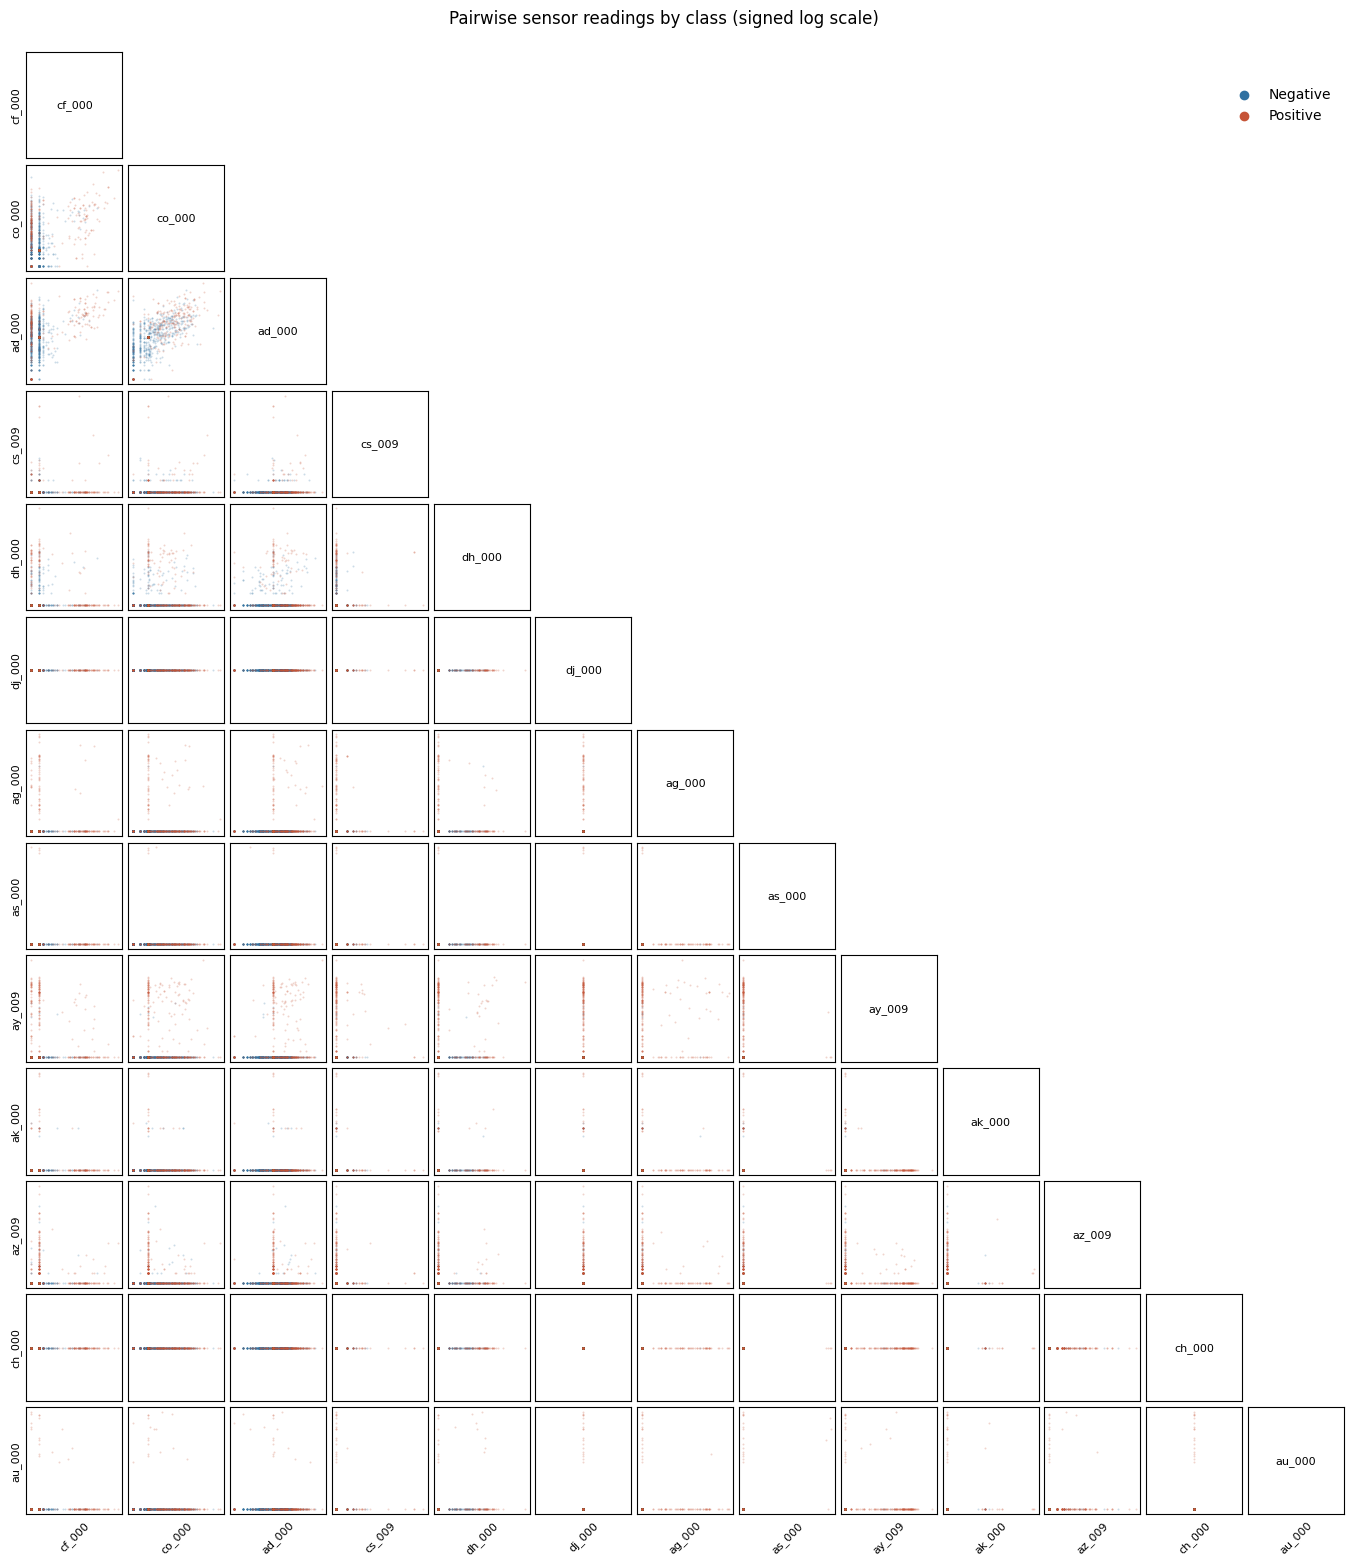

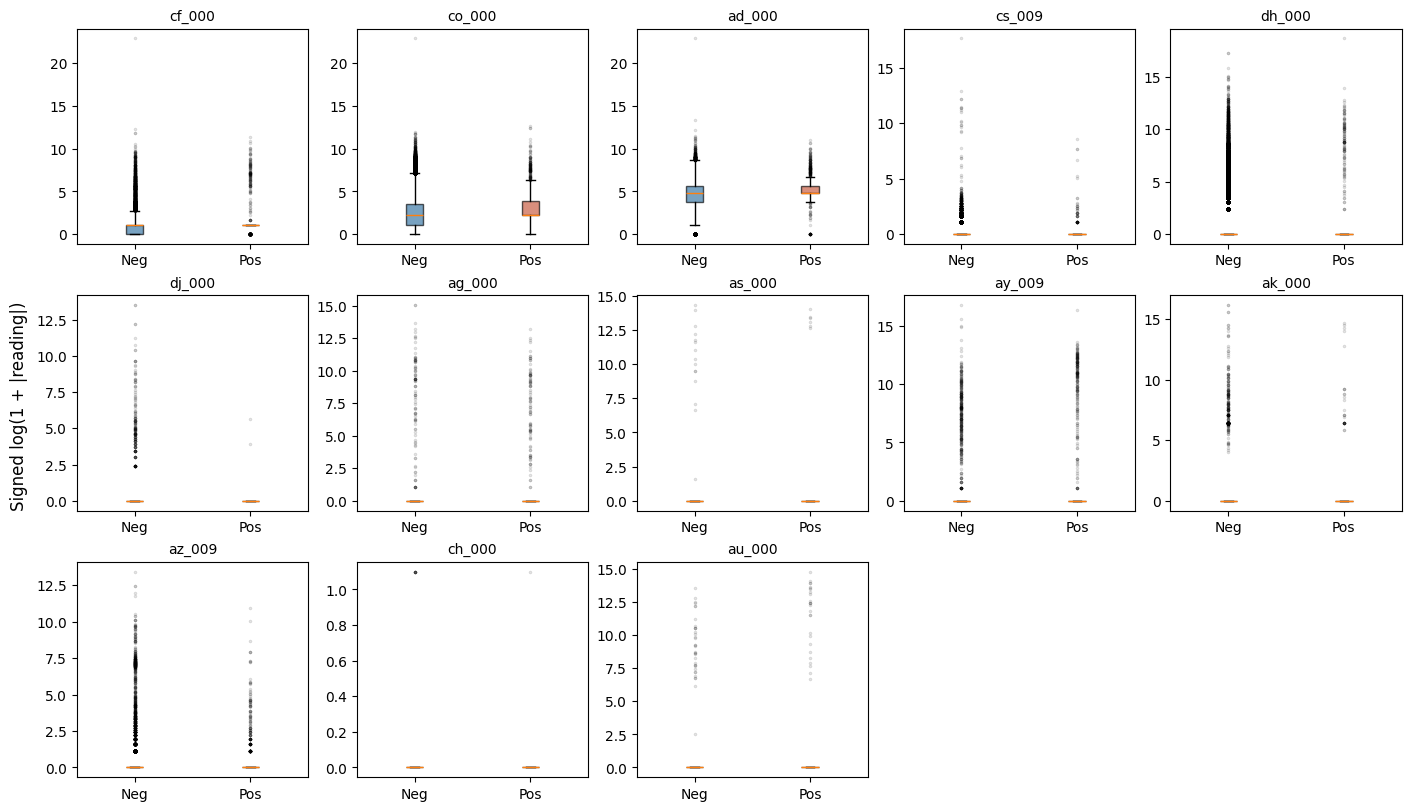

In [6]:
rng=np.random.default_rng(SEED)
groups=[rng.choice(np.flatnonzero(y==i),min(700,int(sum(y==i))),replace=False) for i in (0,1)]
colors=["#3071a1","#c65437"]
vals=transform(train[top].to_numpy())
fig,axes=plt.subplots(13,13,figsize=(17,17))
for i in range(13):
    for j in range(13):
        ax=axes[i,j]
        if i<j: ax.axis("off"); continue
        if i==j: ax.text(.5,.5,top[i],ha="center",va="center",transform=ax.transAxes,fontsize=8)
        else:
            for k,idx in enumerate(groups):
                ax.scatter(vals[idx,j],vals[idx,i],s=2,c=colors[k],alpha=.25,rasterized=True,linewidths=0)
        ax.set_xticks([]); ax.set_yticks([])
        if j==0: ax.set_ylabel(top[i],fontsize=8)
        if i==12: ax.set_xlabel(top[j],fontsize=8,rotation=45)
for k,label in enumerate(["Negative","Positive"]): axes[0,-1].scatter([],[],color=colors[k],label=label)
axes[0,-1].legend(loc="center right",frameon=False)
fig.suptitle("Pairwise sensor readings by class (signed log scale)",y=.995)
fig.subplots_adjust(wspace=.06,hspace=.06,top=.97);showfig("scatter_top13")
fig,axes=plt.subplots(3,5,figsize=(14,8),layout="constrained")
for i,ax in enumerate(axes.flat):
    if i>=13: ax.axis("off"); continue
    b=ax.boxplot([vals[y==k,i] for k in (0,1)],tick_labels=["Neg","Pos"],patch_artist=True,
                 flierprops={"markersize":1.5,"alpha":.15})
    for patch,col in zip(b["boxes"],colors): patch.set_facecolor(col);patch.set_alpha(.65)
    ax.set_title(top[i],fontsize=10)
fig.supylabel("Signed log(1 + |reading|)");showfig("box_top13")
print("Top 13:", ", ".join(top))

The plots show where the classes overlap and where their distributions differ. A large CV measures variability relative to the mean; it does not measure association with the class. The scatterplots alone cannot establish statistical significance. I kept all 170 features for modeling.

## 1(b)(v). Class balance

In [7]:
counts=pd.DataFrame([{"split":k,"negative":sum(v==0),"positive":sum(v==1),"positive_share":np.mean(v)} for k,v in [("Training",y),("Test",yt)]])
table(counts,"class_counts")
answer(f"The training set has {sum(y==0):,} negatives and {sum(y==1):,} positives, a {sum(y==0)/sum(y==1):.0f}:1 imbalance. An always-negative classifier would miss every APS failure.")

,split,negative,positive,positive_share
0,Training,59000,1000,0.01667
1,Test,15625,375,0.02344


The training set has 59,000 negatives and 1,000 positives, a 59:1 imbalance. An always-negative classifier would miss every APS failure.

## 1(c). Random forest without class weights
I used 120 bootstrap trees, square-root feature sampling, and a 0.5 probability cutoff. The ROC curve uses the full range of cutoffs. In all tables, positives are APS failures; rows of each confusion matrix are actual classes and columns are predicted classes.

Train
Test


,Pred neg,Pred pos
Actual neg,59000,0
Actual pos,0,1000


,Pred neg,Pred pos
Actual neg,15606,19
Actual pos,101,274


,split,error,auc,recall,precision
0,Train,0.0000,1.00000,1.00000,1.00000
1,Test,0.0075,0.99434,0.73067,0.93515


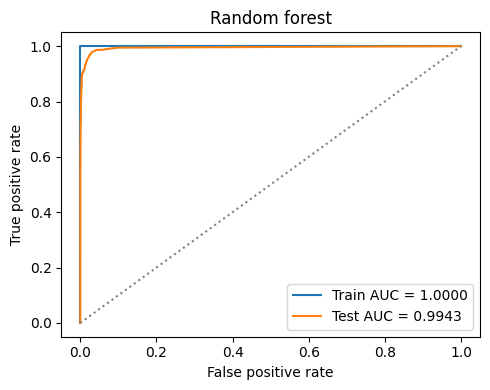

OOB error = 0.622%; test error = 0.750%. The OOB estimate minus the test error is -0.128 percentage points.

In [8]:
metrics=[]; curves={}
def report(name, p_train, p_test, oob=np.nan):
    rows=[]
    for split,truth,p in [("Train",y,p_train),("Test",yt,p_test)]:
        row=evaluate(name,split,truth,p,oob if split=="Train" else np.nan)
        metrics.append(row); rows.append(row)
        curves[name,split]=roc_curve(truth,p)[:2]
        cm=pd.DataFrame([[row["TN"],row["FP"]],[row["FN"],row["TP"]]],
                        index=["Actual neg","Actual pos"],columns=["Pred neg","Pred pos"])
        print(split);display(cm)
    display(pd.DataFrame(rows)[["split","error","auc","recall","precision"]].round(5))
    fig,ax=plt.subplots(figsize=(5,4))
    for r in rows: ax.plot(*curves[name,r["split"]],label=f'{r["split"]} AUC = {r["auc"]:.4f}')
    ax.plot([0,1],[0,1],":",color="gray");ax.set(xlabel="False positive rate",ylabel="True positive rate",title=name)
    ax.legend();fig.tight_layout();showfig(name.lower().replace(" ","_")+"_roc")
    return rows
def forest(name, weight):
    rf=RandomForestClassifier(n_estimators=120,max_features="sqrt",bootstrap=True,
        oob_score=True,class_weight=weight,random_state=SEED,n_jobs=4).fit(X,y)
    rows=report(name,rf.predict_proba(X)[:,1],rf.predict_proba(T)[:,1],1-rf.oob_score_)
    answer(f'OOB error = {1-rf.oob_score_:.3%}; test error = {rows[1]["error"]:.3%}. '
           f'The OOB estimate minus the test error is {100*(1-rf.oob_score_-rows[1]["error"]):+.3f} percentage points.')
    return rows
rf0=forest("Random forest",None)

## 1(d). Random forest with imbalance compensation
Two ways to address imbalance are to give each minority case more weight in the split criterion or to balance the classes by sampling within each bootstrap replicate. I used the first approach: `balanced_subsample` recalculates inverse-frequency class weights for each tree. The data, seed, number of trees, and prediction threshold match 1(c).

Train
Test


,Pred neg,Pred pos
Actual neg,59000,0
Actual pos,0,1000


,Pred neg,Pred pos
Actual neg,15608,17
Actual pos,154,221


,split,error,auc,recall,precision
0,Train,0.00000,1.00000,1.00000,1.00000
1,Test,0.01069,0.99028,0.58933,0.92857


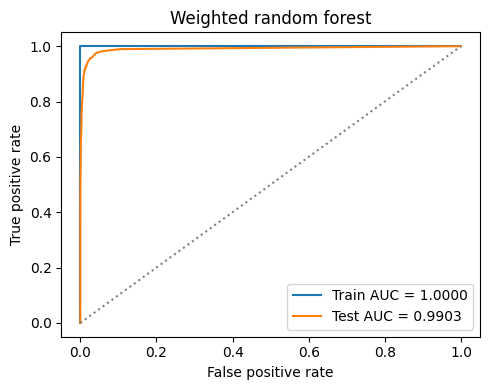

OOB error = 0.798%; test error = 1.069%. The OOB estimate minus the test error is -0.270 percentage points.

On the test set, weighting changed false negatives from 101 to 154 and false positives from 19 to 17. Recall changed from 73.07% to 58.93%; AUC changed from 0.9943 to 0.9903.

In [9]:
rf1=forest("Weighted random forest","balanced_subsample")
a,b=rf0[1],rf1[1]
answer(f'On the test set, weighting changed false negatives from {a["FN"]} to {b["FN"]} and false positives from {a["FP"]} to {b["FP"]}. Recall changed from {a["recall"]:.2%} to {b["recall"]:.2%}; AUC changed from {a["auc"]:.4f} to {b["auc"]:.4f}.')

## 1(e). XGBoost logistic model tree without compensation
At the root I fitted an L1-penalized logistic model using XGBoost's linear booster. A one-split CART tree chooses a Gini-minimizing threshold on its probability score (at least 100 observations per child). A threshold on a logistic score gives a linear boundary in the transformed features. Each child fits its own L1 logistic model and returns its probability; a pure child returns its class. This gives an explicit model tree rather than treating ordinary XGBoost tree leaves as logistic regressions.

I used signed-log features standardized on the fitting fold, 20 single-threaded coordinate-descent rounds per node with a fixed learning rate of 0.08, and no class weights. I selected α by the smallest mean misclassification rate across five stratified folds, choosing the smaller α in a tie. The error at the selected α is a tuning-CV estimate and can be optimistic. The supplied test set played no role in tuning.

Fit rows: 60000  negative: 59000  positive: 1000
Train
Test


,smote,alpha,cv_error,cv_auc
0,False,0.0001,0.010217,0.982762
1,False,0.0010,0.010367,0.979033
2,False,0.0100,0.011533,0.911804


,Pred neg,Pred pos
Actual neg,58849,151
Actual pos,418,582


,Pred neg,Pred pos
Actual neg,15590,35
Actual pos,166,209


,split,error,auc,recall,precision
0,Train,0.00948,0.98427,0.58200,0.79400
1,Test,0.01256,0.99019,0.55733,0.85656


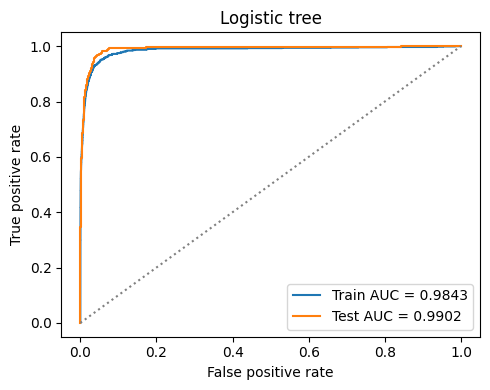

α = 0.0001. Five-fold error = 1.022%; test error = 1.256%. Test minus CV = +0.235 percentage points.

In [10]:
folds=tune(A,y)
folds.to_csv(OUT/"model_tree_cv_folds.csv",index=False)
scores=folds.groupby(["smote","alpha"],as_index=False).agg(cv_error=("error","mean"),cv_auc=("auc","mean"))
scores.to_csv(OUT/"model_tree_cv.csv",index=False)
xa,xb=prep(A,B,mb)
def fit_tree(use):
    grid=scores.loc[scores.smote==use].sort_values(["cv_error","alpha"])
    display(grid.round(6))
    best=grid.iloc[0]; alpha=float(best.alpha)
    xx,yy=SMOTE(random_state=SEED).fit_resample(xa,y) if use else (xa,y)
    name="SMOTE logistic tree" if use else "Logistic tree"
    model=LogisticTree(alpha).fit(xx,yy)
    print("Fit rows:",len(yy)," negative:",sum(yy==0)," positive:",sum(yy==1))
    rows=report(name,model.prob(xa),model.prob(xb))
    answer(f'α = {alpha:g}. Five-fold error = {best.cv_error:.3%}; test error = {rows[1]["error"]:.3%}. '
           f'Test minus CV = {100*(rows[1]["error"]-best.cv_error):+.3f} percentage points.')
    return rows
tree0=fit_tree(False)

## 1(f). Logistic model tree with SMOTE
I used five nearest minority neighbors in standardized, signed-log feature space. Within each training fold, SMOTE interpolates between minority observations until the classes are equal in size. Validation rows remain original and keep their natural class proportions. I repeated the α search and fitted the final model on the complete oversampled training set. Both training and test metrics below use original observations only.

Fit rows: 118000  negative: 59000  positive: 59000
Train
Test


,smote,alpha,cv_error,cv_auc
3,True,0.0001,0.059950,0.977976
4,True,0.0010,0.061283,0.977934
5,True,0.0100,0.066067,0.975143


,Pred neg,Pred pos
Actual neg,55539,3461
Actual pos,47,953


,Pred neg,Pred pos
Actual neg,14728,897
Actual pos,10,365


,split,error,auc,recall,precision
0,Train,0.05847,0.98400,0.95300,0.21590
1,Test,0.05669,0.98634,0.97333,0.28922


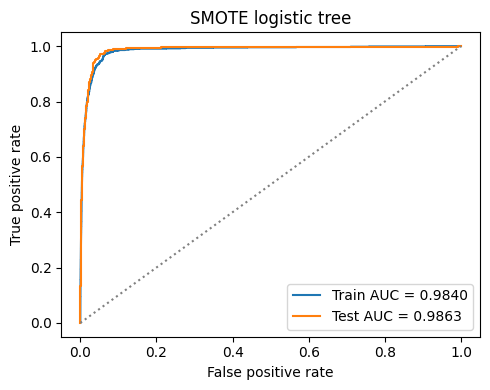

α = 0.0001. Five-fold error = 5.995%; test error = 5.669%. Test minus CV = -0.326 percentage points.

With SMOTE, test false negatives changed from 166 to 10 and false positives from 35 to 897. Recall changed from 55.73% to 97.33%, and error from 1.256% to 5.669%. AUC was 0.9902 without SMOTE and 0.9863 with SMOTE.

,model,split,TN,FP,FN,TP,error,auc,recall,precision,oob_error
0,Random forest,Train,59000,0,0,1000,0.00000,1.00000,1.00000,1.00000,0.00622
1,Random forest,Test,15606,19,101,274,0.00750,0.99434,0.73067,0.93515,NaN
2,Weighted random forest,Train,59000,0,0,1000,0.00000,1.00000,1.00000,1.00000,0.00798
3,Weighted random forest,Test,15608,17,154,221,0.01069,0.99028,0.58933,0.92857,NaN
4,Logistic tree,Train,58849,151,418,582,0.00948,0.98427,0.58200,0.79400,NaN
5,Logistic tree,Test,15590,35,166,209,0.01256,0.99019,0.55733,0.85656,NaN
6,SMOTE logistic tree,Train,55539,3461,47,953,0.05847,0.98400,0.95300,0.21590,NaN
7,SMOTE logistic tree,Test,14728,897,10,365,0.05669,0.98634,0.97333,0.28922,NaN


In [11]:
tree1=fit_tree(True)
a,b=tree0[1],tree1[1]
answer(f'With SMOTE, test false negatives changed from {a["FN"]} to {b["FN"]} and false positives from {a["FP"]} to {b["FP"]}. Recall changed from {a["recall"]:.2%} to {b["recall"]:.2%}, and error from {a["error"]:.3%} to {b["error"]:.3%}. AUC was {a["auc"]:.4f} without SMOTE and {b["auc"]:.4f} with SMOTE.')
table(pd.DataFrame(metrics),"classification_results")

## 2. ISLR 6.6, Exercise 3 — Relaxing the lasso constraint

Starting at $s=0$, the intercept is free and every slope is zero. As $s$ increases, the feasible set $\sum_j|\beta_j|\le s$ grows.

| Part | Choice | Reason |
|---|---|---|
| (a) Training RSS | **iv — decreases** | The old fit stays feasible, so the minimum RSS cannot rise. It levels off when the constraint stops binding. |
| (b) Test RSS | **ii — typically U-shaped** | Relaxing a tight constraint can reduce underfitting; eventually the extra variability can outweigh the reduction in bias. The exact curve depends on the data. |
| (c) Variance | **iii — generally increases** | With less shrinkage, the fitted coefficients respond more to changes in the training sample. |
| (d) Squared bias | **iv — generally decreases** | The slopes can move away from zero toward the underlying signal. |
| (e) Irreducible error | **v — remains constant** | Changing the estimator does not change the noise in the response. |

## 3. ISLR 6.6, Exercise 5 — Two identical predictors

Let $x_i=x_{i1}=x_{i2}$, $t=\beta_1+\beta_2$, and $R(t)=\sum_{i=1}^2(y_i-x_it)^2$. Centering gives $\hat\beta_0=0$.

**(a)** The ridge objective is $\min_{\beta_1,\beta_2}\;R(\beta_1+\beta_2)+\lambda(\beta_1^2+\beta_2^2)$.

**(b)** For a fixed sum $t$, $\beta_1^2+\beta_2^2=t^2/2+(\beta_1-\beta_2)^2/2$. With $\lambda>0$, the penalty is smallest only at $\hat\beta_1=\hat\beta_2=t/2$.

**(c)** The lasso objective is $\min_{\beta_1,\beta_2}\;R(\beta_1+\beta_2)+\lambda(|\beta_1|+|\beta_2|)$.

**(d)** For a fixed $t$, the smallest possible penalty is $\lambda|t|$. Every same-sign split attains it. If $t^*$ minimizes $R(t)+\lambda|t|$, all pairs $(a,t^*-a)$ with $a$ between $0$ and $t^*$ are solutions. For $t^*\ne0$ there are infinitely many such pairs, all with the same fitted values. If shrinkage gives $t^*=0$ and $\lambda>0$, only $(0,0)$ minimizes the objective.

## 4. ISLR 8.4, Exercise 5 — Aggregating ten trees
**Majority vote: Red.** Six trees assign Red a probability above 0.5 and four vote Green.  
**Mean probability: Green.** The ten Red probabilities sum to 4.50, so the mean is 0.45. The low Red probabilities pull the average below 0.5 despite the vote count.

## 5. ISLR 9.7, Exercise 3 — Maximal margin classifier

**(a)–(b)** The numbered points and the optimal separator appear in the left panel. The inner class boundaries lie on $x_2=x_1$ (Red) and $x_2=x_1-1$ (Blue). Their closest segments have overlapping perpendicular projections. The bisector $x_2=x_1-0.5$ therefore attains half the distance between the two class hulls.

**(c)** Let $f(x)=0.5-x_1+x_2$. Predict Red for $f(x)>0$ and Blue otherwise; $(\beta_0,\beta_1,\beta_2)=(0.5,-1,1)$.

**(d)** The dashed lines are the margins. The perpendicular distance from the separator to either margin is $0.5/\sqrt{2}$; the full width is $1/\sqrt{2}$.

**(e)** The observations on the margins are Red **2, 3** and Blue **5, 6**.

**(f)** Observation 7 at $(4,1)$ lies strictly beyond the Blue margin. A small move that keeps it there leaves the closest points and the optimal separator unchanged.

**(g)** The line $x_2=x_1-0.25$ also separates both classes. Its nearest Red point is only $0.25/\sqrt{2}$ away, so it has a smaller margin.

**(h)** Add a Blue point at $(2.5,3.25)$, inside the triangle formed by Red points 1, 2, and 4. A half-plane containing those Red points also contains the new Blue point, so no line separates the augmented data.

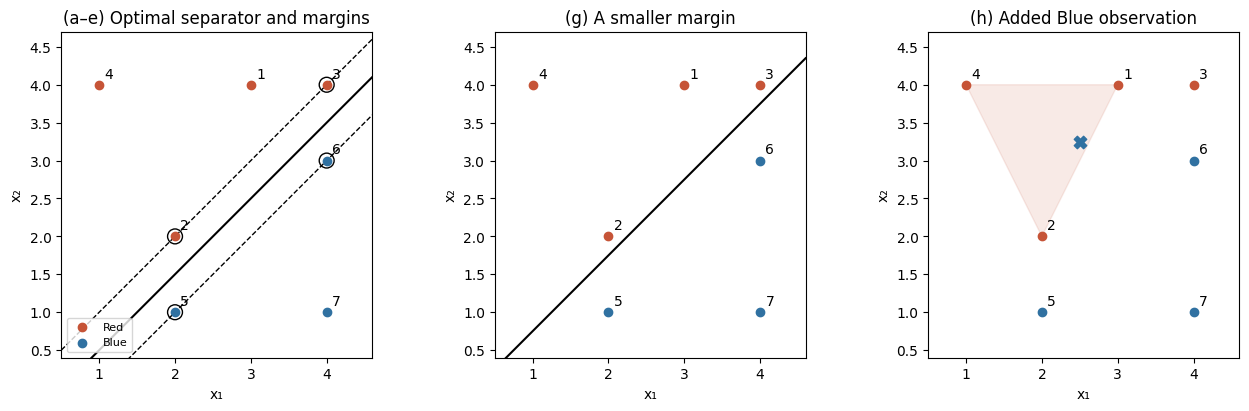

In [12]:
points=np.array([[3,4],[2,2],[4,4],[1,4],[2,1],[4,3],[4,1]])
fig,axes=plt.subplots(1,3,figsize=(13,4),layout="constrained")
xx=np.linspace(.5,4.6,100)
for i,ax in enumerate(axes):
    for mask,col,label in [(np.arange(7)<4,"#c65437","Red"),(np.arange(7)>=4,"#3071a1","Blue")]:
        ax.scatter(*points[mask].T,color=col,label=label,zorder=3)
    for j,(x1,x2) in enumerate(points,1): ax.annotate(str(j),(x1+.07,x2+.09))
    ax.set(xlim=(.5,4.6),ylim=(.4,4.7),xlabel="x₁",ylabel="x₂",aspect="equal")
    if i==0:
        ax.plot(xx,xx-.5,"k-");ax.plot(xx,xx,"k--",lw=1);ax.plot(xx,xx-1,"k--",lw=1)
        ax.scatter(*points[[1,2,4,5]].T,s=115,facecolors="none",edgecolors="black")
        ax.set_title("(a–e) Optimal separator and margins")
    elif i==1:
        ax.plot(xx,xx-.25,color="black");ax.set_title("(g) A smaller margin")
    else:
        ax.fill(*points[[0,1,3]].T,color="#c65437",alpha=.12)
        ax.scatter(2.5,3.25,marker="X",s=80,c="#3071a1")
        ax.set_title("(h) Added Blue observation")
axes[0].legend(loc="lower left",fontsize=8);showfig("max_margin")

## 6. Extra practice

### ISLR 5.4, Exercise 2 — Bootstrap inclusion
**(a), (b)** On either draw, the probability of missing observation $j$ is $(n-1)/n$: all $n$ observations are equally likely and drawing with replacement restores the same population.  
**(c)** Independence gives $P(j\text{ absent})=(1-1/n)^n$.  
**(d)–(g)** The inclusion probability is $1-(1-1/n)^n$. It decreases from 1 toward $1-e^{-1}\approx0.63212$.  
**(h)** I estimated inclusion by checking whether observation 4 appeared in each of 10,000 bootstrap samples of size 100.

n=5: 0.672320
n=100: 0.633968
n=10000: 0.632139


Observed inclusion was 0.6238, compared with the theoretical 0.6340.

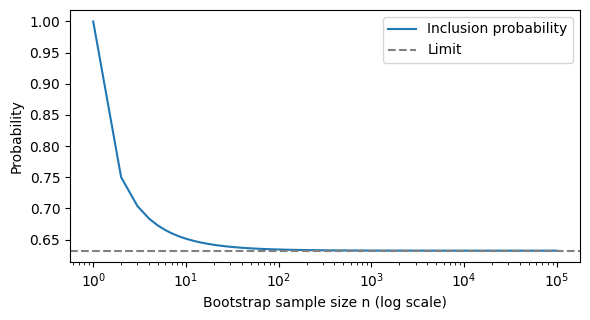

In [13]:
n=np.arange(1,100001)
prob=1-(1-1/n)**n
for size in (5,100,10000): print(f"n={size}: {prob[size-1]:.6f}")
sim=np.random.default_rng(SEED).integers(1,101,size=(10000,100))
rate=(sim==4).any(axis=1).mean()
answer(f'Observed inclusion was {rate:.4f}, compared with the theoretical {prob[99]:.4f}.')
fig,ax=plt.subplots(figsize=(6,3.3));ax.semilogx(n,prob,label="Inclusion probability")
ax.axhline(1-np.exp(-1),ls="--",color="gray",label="Limit")
ax.set(xlabel="Bootstrap sample size n (log scale)",ylabel="Probability");ax.legend()
fig.tight_layout();showfig("bootstrap")

### ISLR 6.8, Exercise 4 — Increasing the ridge penalty

**(a) iii.** Training RSS is nondecreasing: ordinary least squares already minimizes it at $\lambda=0$.  
**(b) ii.** Test RSS typically falls and then rises. Moderate shrinkage reduces variance; too much removes signal.  
**(c) iv.** Variance decreases as the slopes are pulled toward zero.  
**(d) iii.** Squared bias generally increases as the model loses flexibility.  
**(e) v.** Irreducible error does not depend on $\lambda$.

### ISLR 8.4, Exercise 4 — Trees and partitions
**(a)** In the left diagram, Yes takes the left branch. Splitting first at x₁ = 1 isolates the region with mean 5.  
**(b)** In the right diagram, the first horizontal cut is x₂ = 1; the cut at x₂ = 2 applies only to its upper branch. Each region is labeled with its predicted mean.

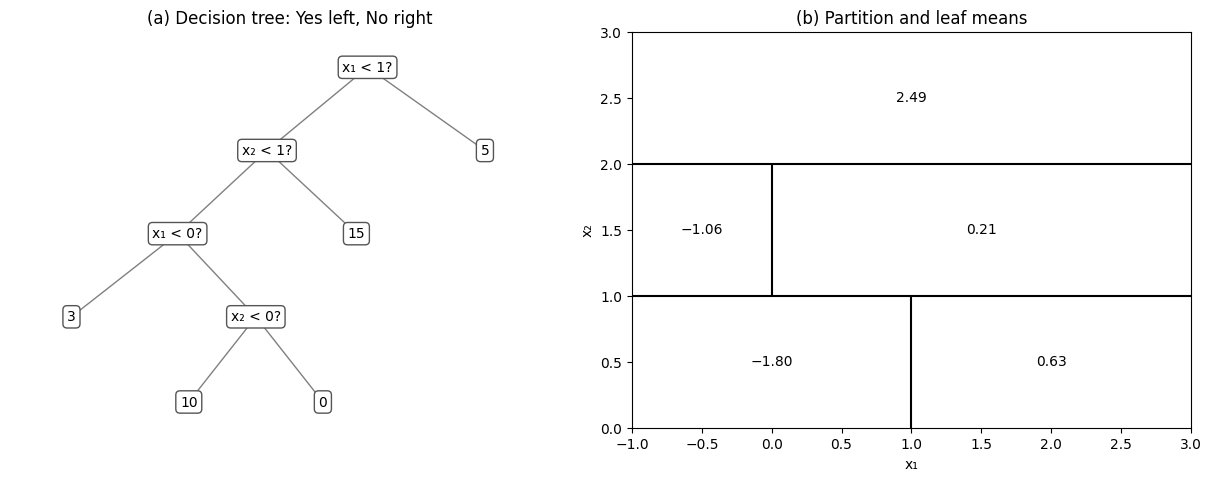

In [14]:
fig,(ax,bx)=plt.subplots(1,2,figsize=(12,4.7),layout="constrained")
nodes={"a":(.64,.91,"x₁ < 1?"),"b":(.46,.70,"x₂ < 1?"),"c":(.85,.70,"5"),
"d":(.30,.49,"x₁ < 0?"),"e":(.62,.49,"15"),"f":(.11,.28,"3"),
"g":(.44,.28,"x₂ < 0?"),"h":(.32,.065,"10"),"i":(.56,.065,"0")}
for u,v in [("a","b"),("a","c"),("b","d"),("b","e"),("d","f"),("d","g"),("g","h"),("g","i")]:
    x1,y1,_=nodes[u];x2,y2,_=nodes[v];ax.plot([x1,x2],[y1,y2],c="gray",lw=1)
for x1,x2,t in nodes.values():ax.text(x1,x2,t,ha="center",va="center",bbox=dict(boxstyle="round,pad=.3",fc="white",ec="#555"))
ax.set(xlim=(0,1),ylim=(0,1),title="(a) Decision tree: Yes left, No right");ax.axis("off")
bx.set(xlim=(-1,3),ylim=(0,3),xlabel="x₁",ylabel="x₂",title="(b) Partition and leaf means")
bx.hlines([1,2],-1,3,color="black");bx.vlines(1,0,1,color="black");bx.vlines(0,1,2,color="black")
for x1,x2,t in [(0,.5,"−1.80"),(2,.5,"0.63"),(-.5,1.5,"−1.06"),(1.5,1.5,"0.21"),(1,2.5,"2.49")]:
    bx.text(x1,x2,t,ha="center",va="center")
showfig("tree_partition")

### ISLR 9.7, Exercise 2 — A nonlinear boundary

**(a), (b)** The boundary is a circle of radius 2 centered at $(-1,2)$. Squared distances greater than 4 are outside; values at most 4 are inside or on the boundary.  
**(c)** The squared distances at $(0,0),(-1,1),(2,2),(3,8)$ are $5,1,9,52$, giving **Blue, Red, Blue, Blue**, respectively.  
**(d)** Expanding and subtracting 4 gives $1+2x_1+x_1^2-4x_2+x_2^2=0$. This is a hyperplane in the transformed predictors $(x_1,x_1^2,x_2,x_2^2)$.

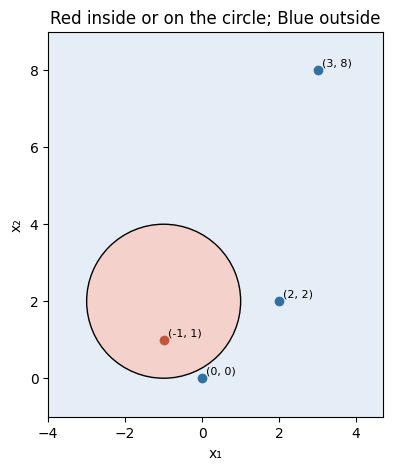

In [15]:
fig,ax=plt.subplots(figsize=(5,5));ax.set_facecolor("#e5eef6")
ax.add_patch(plt.Circle((-1,2),2,facecolor="#f4d1ca",edgecolor="black"))
for x1,x2 in [(0,0),(-1,1),(2,2),(3,8)]:
    ax.scatter(x1,x2,color=("#3071a1" if (1+x1)**2+(2-x2)**2>4 else "#c65437"))
    ax.annotate(f"({x1}, {x2})",(x1+.1,x2+.1),fontsize=8)
ax.set(xlim=(-4,4.7),ylim=(-1,9),aspect="equal",xlabel="x₁",ylabel="x₂",
       title="Red inside or on the circle; Blue outside")
showfig("circle")

## References
- [Scania APS Failure data, UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/421/aps+failure+at+scania+trucks)
- [scikit-learn: Imputation of missing values](https://scikit-learn.org/stable/modules/impute.html)
- [Chen, Liaw & Breiman: Using Random Forest to Learn Imbalanced Data](https://statistics.berkeley.edu/sites/default/files/tech-reports/666.pdf)
- [XGBoost: Linear booster parameters](https://xgboost.readthedocs.io/en/stable/parameter.html#parameters-for-linear-booster-booster-gblinear)
- [imbalanced-learn: Data leakage during resampling](https://imbalanced-learn.org/stable/common_pitfalls.html)
- [James, Witten, Hastie & Tibshirani: An Introduction to Statistical Learning](https://www.statlearning.com/)